# Apples and oranges: a conditional autoencoder

Every picture in this notebook shows one fruit on white paper: an **apple**, drawn as a red circle, or an **orange**, drawn as an orange circle. Three numbers say everything about a picture:

* $x$ and $y$, where the fruit sits, as fractions of the frame's width and height measured from its bottom left corner,
* the **label**, which fruit it is: $0$ for an apple, $1$ for an orange.

The pictures are synthetic: a few lines of Python below draw them, with a seeded random generator, so every run sees the same fruit.

A **conditional autoencoder** is an autoencoder that is told the label. The **encoder** squeezes a picture of $32 \times 32$ pixels, with its label, into $16$ numbers, the **code**. The **decoder** rebuilds the picture from the code and the label. If the decoder takes *which* fruit from the label, we can take an apple, keep its code, flip its label, and get an orange in the same place.

But $16$ numbers leave room for the code to say which fruit it is as well. We train the same autoencoder twice, once without and once with a penalty that stands in for the KL term of a variational autoencoder, and see which one listens to the label.

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
import ipywidgets as widgets

## 1. Drawing a fruit

A colour picture is three grids of $32 \times 32$ numbers between $0$ and $1$: how much red, green and blue light each pixel gives, so white paper is $(1, 1, 1)$. We store each picture as **paint on white paper** instead: white minus the colour, so that bare paper is $(0, 0, 0)$ and most of the numbers of a picture are $0$. That makes the autoencoder's work much easier. `draw_fruit(x, y, label)` paints a disc in the colour of the fruit, with a soft rim, and a dark outline round it. The outline is the same for both fruits, so it shows *where* a fruit is without saying *which* fruit it is. `show` turns the paint back into the colours you see.

In [2]:
# Where every pixel sits: u runs from 0 at the left edge to 1 at the right edge,
# v from 0 at the bottom edge to 1 at the top edge.
u, v = np.meshgrid(np.linspace(0, 1, 32), np.linspace(1, 0, 32))

FRUIT = ["apple", "orange"]                 # label 0 is an apple, label 1 an orange
COLOUR = np.array([[0.80, 0.10, 0.10],      # an apple is red
                   [1.00, 0.60, 0.05]])     # an orange is orange


def draw_fruit(x, y, label):
    # The distance of every pixel from (x, y), in units of the fruit's radius, 0.15.
    distance = np.sqrt((u - x) ** 2 + (v - y) ** 2) / 0.15
    disc = np.clip(4 * (1 - distance), 0, 1)[:, :, None]                 # 1 inside, fading out at the rim
    outline = np.clip(1 - 6 * np.abs(distance - 0.9), 0, 1)[:, :, None]   # a thin ring just inside the rim
    fruit_paint = disc * (1 - COLOUR[label])    # the paint: white minus the colour of the fruit
    return (1 - outline) * fruit_paint + outline * 0.8   # and dark grey painted over it on the outline

## 2. Five thousand fruit

We draw $x$, $y$ and the label at random and paint one fruit for each. The autoencoder sees the pictures and the labels; we keep the $x$ and $y$ behind each picture, `truth`, to caption the pictures and to draw the other fruit in the same place later.

In [3]:
rng = np.random.default_rng(seed=0)   # seeded: the same 5000 fruit on every computer

# One row (x, y) per fruit, both between 0.25 and 0.75, and one label, 0 or 1, per fruit.
truth = rng.uniform(low=0.25, high=0.75, size=(5000, 2))
labels = rng.integers(0, 2, size=5000)

pictures = np.array([draw_fruit(x, y, label) for (x, y), label in zip(truth, labels)])
pictures = torch.tensor(pictures, dtype=torch.float32)
labels = torch.tensor(labels, dtype=torch.float32)[:, None]   # one column of 0s and 1s
print(pictures.shape, labels.shape)

torch.Size([5000, 32, 32, 3]) torch.Size([5000, 1])


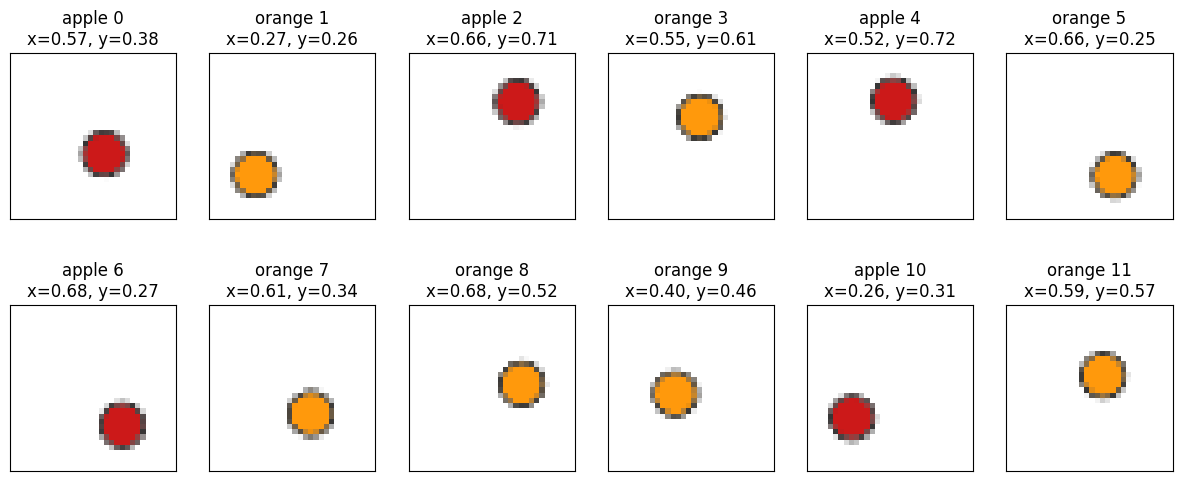

In [4]:
def show(ax, picture, title):
    ax.imshow((1 - picture).clamp(0, 1))   # white minus the paint; a rebuilt value can stray outside [0, 1]
    ax.set(xticks=[], yticks=[], title=title)


fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    x, y = truth[i]
    show(ax, pictures[i], f"{FRUIT[int(labels[i])]} {i}\nx={x:.2f}, y={y:.2f}")
plt.show()

## 3. The conditional autoencoder

The encoder lays the picture out as one list of $32 \times 32 \times 3 = 3072$ numbers, puts the label at the end, and passes the $3073$ numbers through three layers, the last of which has $16$ outputs: the **code** of the picture. The decoder takes the $16$ numbers of a code with the label after them and runs the same way backwards, to $3072$ numbers that it folds back into a $32 \times 32$ colour picture. On the slides the encoder is $\varphi$ and the decoder is $\varphi^{-1}$; here both of them are also told the label.

`train(weight)` builds the two networks and trains them with the loop of weekend 1: while the miss is too big, take a step. The miss is the squared difference between a rebuilt pixel value and the original one, averaged over all the pixel values of $64$ fruit picked at random. The loss adds a second term to the miss: the squared length of each code, $z_1^2 + z_2^2 + \dots + z_{16}^2$, averaged over the $64$ fruit and multiplied by `weight`. It pulls every code towards $0$, as the KL term of a variational autoencoder does. With the spread of a VAE fixed at $1$, the KL term is exactly half this squared length.

`redraw` encodes pictures with their own labels and decodes them with the labels we choose.

In [5]:
def train(weight):
    torch.manual_seed(0)   # seeded: the same starting weights on every computer, and the same batches

    encoder = nn.Sequential(
        nn.Linear(3072 + 1, 256), nn.ReLU(),    # the 3072 pixel values, then the label
        nn.Linear(256, 64), nn.ReLU(),
        nn.Linear(64, 16),                      # the code: 16 numbers
    )
    decoder = nn.Sequential(
        nn.Linear(16 + 1, 64), nn.ReLU(),       # the 16 numbers of the code, then the label
        nn.Linear(64, 256), nn.ReLU(),
        nn.Linear(256, 3072),                   # 3072 numbers, three per pixel
        nn.Unflatten(1, (32, 32, 3)),           # folded back into a 32 x 32 colour picture
    )
    optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=0.002)

    miss = 1.0                                                     # any start above the threshold
    while miss > 0.003:
        rows = torch.randint(0, 5000, (64,))                       # 64 fruit picked at random
        batch, batch_labels = pictures[rows], labels[rows]
        codes = encoder(torch.cat([batch.flatten(1), batch_labels], dim=1))
        rebuilt = decoder(torch.cat([codes, batch_labels], dim=1))
        miss = ((rebuilt - batch) ** 2).mean()                     # the average squared miss
        length = (codes ** 2).sum(dim=1).mean()                    # the average squared length of a code
        loss = miss + weight * length
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        print(f"\raverage squared miss: {miss.item():.4f}   squared length of a code: {length.item():.3f}", end="")
    print()
    return encoder, decoder


def redraw(encoder, decoder, pictures, labels, new_labels):
    # Encode the pictures with their own labels, then decode them with new_labels.
    codes = encoder(torch.cat([pictures.flatten(1), labels], dim=1))
    return decoder(torch.cat([codes, new_labels], dim=1)).detach()

## 4. Training it twice

First without the penalty, `weight=0`: a long code costs nothing. Then with it, `weight=0.001`. Both start from the same weights and see the same batches of fruit, so the weight is the only difference between them.

In [6]:
encoder_0, decoder_0 = train(weight=0)        # without the penalty
encoder, decoder = train(weight=0.001)        # with the penalty

average squared miss: 0.0030   squared length of a code: 27.045
average squared miss: 0.0030   squared length of a code: 0.129


## 5. Apples into oranges

Six apples and six oranges from the data, through the autoencoder trained with the penalty. Each fruit is drawn from its code twice: once with its own label, and once with the label flipped.

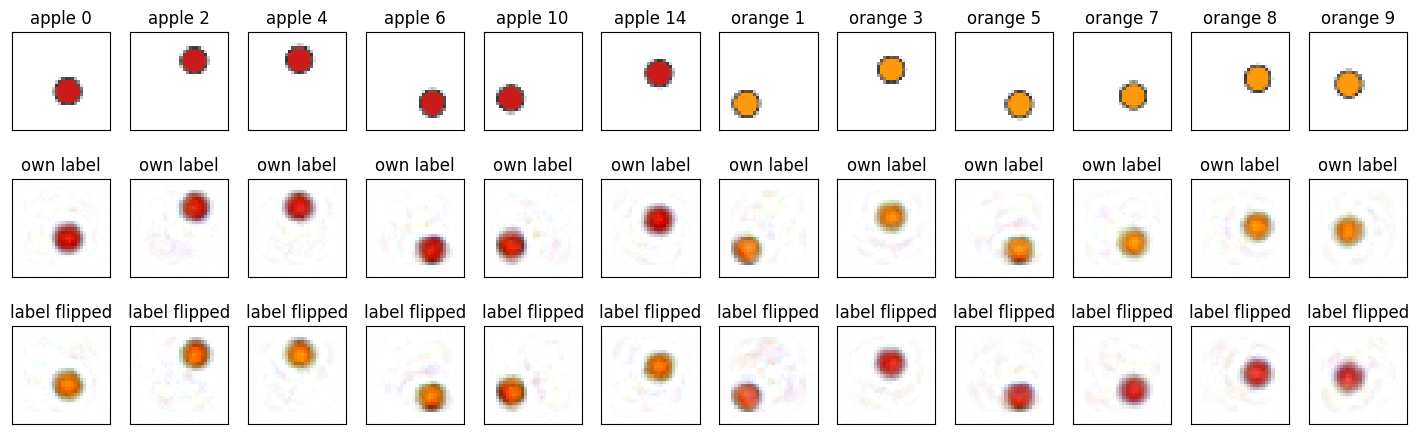

In [7]:
some = torch.cat([torch.nonzero(labels[:, 0] == 0)[:6, 0],    # the first 6 apples
                  torch.nonzero(labels[:, 0] == 1)[:6, 0]])   # the first 6 oranges
own = redraw(encoder, decoder, pictures[some], labels[some], labels[some])
flipped = redraw(encoder, decoder, pictures[some], labels[some], 1 - labels[some])

fig, axes = plt.subplots(3, 12, figsize=(18, 5.4))
for col, i in enumerate(some.tolist()):
    show(axes[0, col], pictures[i], f"{FRUIT[int(labels[i])]} {i}")
    show(axes[1, col], own[col], "own label")
    show(axes[2, col], flipped[col], "label flipped")
plt.show()

## 6. Which one listens to the label?

Flip the label of all $5000$ fruit, with each autoencoder. A flip **worked** if the picture the decoder draws is closer to the other fruit, drawn by `draw_fruit` in the same place, than to the fruit we started from.

Without the penalty, the $16$ numbers have room to say which fruit it is as well as where it is, and the decoder learns to take the fruit partly from the code: flip the label and some pictures come out in between, half apple and half orange. With the penalty every number of the code costs, so the code keeps less of what the label already says, and the decoder takes the fruit from the label.

without the penalty: 4388 of 5000 flips worked
with the penalty:    4894 of 5000 flips worked


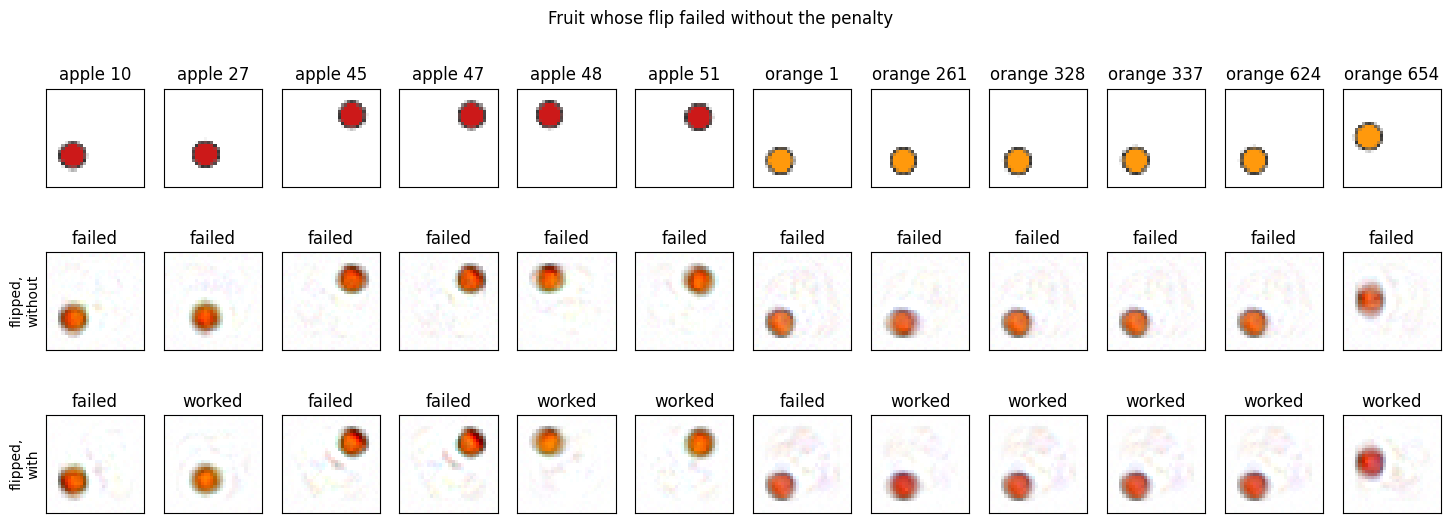

In [8]:
other = np.array([draw_fruit(x, y, 1 - int(label)) for (x, y), label in zip(truth, labels[:, 0])])
other = torch.tensor(other, dtype=torch.float32)    # every fruit's other fruit, in the same place

flipped_0 = redraw(encoder_0, decoder_0, pictures, labels, 1 - labels)
flipped = redraw(encoder, decoder, pictures, labels, 1 - labels)
worked_0 = ((flipped_0 - other) ** 2).mean(dim=(1, 2, 3)) < ((flipped_0 - pictures) ** 2).mean(dim=(1, 2, 3))
worked = ((flipped - other) ** 2).mean(dim=(1, 2, 3)) < ((flipped - pictures) ** 2).mean(dim=(1, 2, 3))
print(f"without the penalty: {int(worked_0.sum())} of 5000 flips worked")
print(f"with the penalty:    {int(worked.sum())} of 5000 flips worked")

failed = torch.nonzero(~worked_0)[:, 0]
some = torch.cat([failed[labels[failed, 0] == 0][:6],   # 6 apples whose flip failed without the penalty
                  failed[labels[failed, 0] == 1][:6]])  # and 6 such oranges
fig, axes = plt.subplots(3, 12, figsize=(18, 6))
for col, i in enumerate(some.tolist()):
    show(axes[0, col], pictures[i], f"{FRUIT[int(labels[i])]} {i}")
    show(axes[1, col], flipped_0[i], "worked" if worked_0[i] else "failed")
    show(axes[2, col], flipped[i], "worked" if worked[i] else "failed")
axes[1, 0].set_ylabel("flipped,\nwithout")
axes[2, 0].set_ylabel("flipped,\nwith")
fig.suptitle("Fruit whose flip failed without the penalty")
plt.show()

Does the code itself know the fruit? Take each fruit's $10$ nearest neighbours in the code, the $10$ fruit whose $16$ numbers are closest to its own, and count how many are the same fruit. A code that knew nothing about the fruit would give about half; a code that knew it perfectly, all of them.

In [9]:
def same_fruit_nearby(encoder):
    codes = encoder(torch.cat([pictures.flatten(1), labels], dim=1)).detach()
    distances = torch.cdist(codes, codes)
    distances.fill_diagonal_(float("inf"))                  # a fruit is not its own neighbour
    nearest = distances.topk(10, largest=False).indices     # the 10 nearest codes of every fruit
    return (labels[nearest, 0] == labels).float().mean().item()


print(f"without the penalty: {same_fruit_nearby(encoder_0):.0%} of the nearest neighbours are the same fruit")
print(f"with the penalty:    {same_fruit_nearby(encoder):.0%} of the nearest neighbours are the same fruit")

without the penalty: 97% of the nearest neighbours are the same fruit
with the penalty:    89% of the nearest neighbours are the same fruit


## 7. Flip any fruit

Pick a fruit with the slider, choose the label to decode it with, and choose the autoencoder. On the left is the fruit, on the right what the decoder draws from its code.

In [10]:
models = {"with the penalty": (encoder, decoder), "without the penalty": (encoder_0, decoder_0)}

fruit = widgets.IntSlider(min=0, max=4999, description="fruit", continuous_update=False)
label = widgets.ToggleButtons(options=[("apple", 0), ("orange", 1)], description="label")
model = widgets.ToggleButtons(options=list(models), description="model")


def pick_fruit(change):
    # A new fruit was picked: set the label to its own.
    label.value = int(labels[fruit.value])


def draw(fruit, label, model):
    x, y = truth[fruit]
    encoder, decoder = models[model]
    new_picture = redraw(encoder, decoder, pictures[fruit:fruit + 1], labels[fruit:fruit + 1],
                         torch.tensor([[float(label)]]))[0]
    fig, (left, right) = plt.subplots(1, 2, figsize=(9, 4.8))
    show(left, pictures[fruit], f"{FRUIT[int(labels[fruit])]} {fruit}: x={x:.2f} y={y:.2f}")
    show(right, new_picture, f"decoded with the label {label} ({FRUIT[label]})\n{model}")
    plt.show()


fruit.observe(pick_fruit, names="value")
pick_fruit(None)   # start on fruit 0
widgets.interact(draw, fruit=fruit, label=label, model=model);

interactive(children=(IntSlider(value=0, continuous_update=False, description='fruit', max=4999), ToggleButton…